# How Encoder Models Like BERT Work

**What you'll learn**
- How an encoder reads a sentence from both sides
- How an encoder is trained: hide a token, fill it back in
- Why the same word gets a different vector in a different sentence
- How a text becomes one vector, and a head turns it into a decision

## Setup
- ModernBERT-base: an encoder, the kind of model that decides
- No training in this notebook, so gradients are switched off

In [1]:
import torch
import matplotlib.pyplot as plt
from transformers import (AutoTokenizer,
                          AutoModel,
                          AutoModelForSequenceClassification,
                          pipeline,
                          logging)

torch.set_grad_enabled(False)
logging.set_verbosity_error()

In [2]:
MODEL = "answerdotai/ModernBERT-base"

tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModel.from_pretrained(MODEL, device_map="cuda")
model

ModernBertModel(
  (embeddings): ModernBertEmbeddings(
    (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
    (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
    (drop): Dropout(p=0.0, inplace=False)
  )
  (layers): ModuleList(
    (0): ModernBertEncoderLayer(
      (attn_norm): Identity()
      (attn): ModernBertAttention(
        (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
        (Wo): Linear(in_features=768, out_features=768, bias=False)
        (out_drop): Identity()
      )
      (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (mlp): ModernBertMLP(
        (Wi): Linear(in_features=768, out_features=2304, bias=False)
        (act): GELUActivation()
        (drop): Dropout(p=0.0, inplace=False)
        (Wo): Linear(in_features=1152, out_features=768, bias=False)
      )
    )
    (1-21): 21 x ModernBertEncoderLayer(
      (attn_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (attn): ModernBertAt

## How an Encoder Tokenizes Text
- The encoder adds `[CLS]` at the start and `[SEP]` at the end

In [3]:
ids = tok("It's time for tea.")["input_ids"]
tok.convert_ids_to_tokens(ids)

['[CLS]', 'It', "'s", 'Ġtime', 'Ġfor', 'Ġtea', '.', '[SEP]']

- A batch needs equal lengths, so the shorter text gets `[PAD]`

In [4]:
x = tok(["It's time for tea.", "It's time for a cup of tea."], padding=True)
tok.convert_ids_to_tokens(x["input_ids"][0])

['[CLS]',
 'It',
 "'s",
 'Ġtime',
 'Ġfor',
 'Ġtea',
 '.',
 '[SEP]',
 '[PAD]',
 '[PAD]',
 '[PAD]']

In [5]:
x["attention_mask"]

[[1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]

- 1 for real tokens, 0 for padding: attention never looks at `[PAD]`

## Encoder Attention Looks Both Ways, No Causal Mask
- No causal mask: a token can look at the words after it

In [6]:
model.set_attn_implementation("eager")

x = tok("The cat sat on the mat because it was tired.", return_tensors="pt").to("cuda")
response = model(**x, output_attentions=True)
len(response.attentions), response.attentions[0].shape

(22, torch.Size([1, 12, 13, 13]))

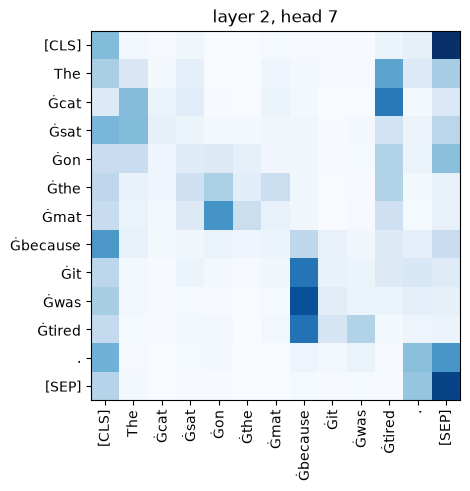

In [7]:
tokens = tok.convert_ids_to_tokens(x["input_ids"][0])
A = response.attentions[2][0, 7].float().cpu()  # layer 2, first text, head 7

plt.imshow(A, cmap="Blues")
plt.xticks(range(len(tokens)), tokens, rotation=90)
plt.yticks(range(len(tokens)), tokens)
plt.title("layer 2, head 7")
plt.show()

- Find the row for `Ġcat`: it looks ahead to `Ġtired`

## Masked Word Prediction: Fill In [MASK]

In [8]:
fill = pipeline("fill-mask", model=MODEL, device_map="cuda")

fill("The capital of France is [MASK].")

[{'score': 0.9233400225639343,
  'token': 7785,
  'token_str': ' Paris',
  'sequence': 'The capital of France is Paris.'},
 {'score': 0.0359475240111351,
  'token': 42268,
  'token_str': ' Lyon',
  'sequence': 'The capital of France is Lyon.'},
 {'score': 0.023051084950566292,
  'token': 23397,
  'token_str': ' Nancy',
  'sequence': 'The capital of France is Nancy.'},
 {'score': 0.006168763153254986,
  'token': 29902,
  'token_str': ' Nice',
  'sequence': 'The capital of France is Nice.'},
 {'score': 0.0025843221228569746,
  'token': 20159,
  'token_str': ' Orleans',
  'sequence': 'The capital of France is Orleans.'}]

- `Paris` wins by far

In [9]:
fill("I was charged [MASK] for one order.")

[{'score': 0.08371848613023758,
  'token': 370,
  'token_str': ' $',
  'sequence': 'I was charged $ for one order.'},
 {'score': 0.036309946328401566,
  'token': 7019,
  'token_str': ' twice',
  'sequence': 'I was charged twice for one order.'},
 {'score': 0.026476478204131126,
  'token': 2583,
  'token_str': ' money',
  'sequence': 'I was charged money for one order.'},
 {'score': 0.024666978046298027,
  'token': 4465,
  'token_str': ' extra',
  'sequence': 'I was charged extra for one order.'},
 {'score': 0.02466323785483837,
  'token': 760,
  'token_str': ' only',
  'sequence': 'I was charged only for one order.'}]

## How an Encoder Is Trained: Masked Language Modelling
- Hide a token; the loss is −log p of the real token at the gap
- `-100` means no loss at that position, so only the gap counts

In [10]:
x = tok("The capital of France is [MASK].", return_tensors="pt").to("cuda")
gap = x["input_ids"] == tok.mask_token_id  # True only at [MASK]
paris = tok.convert_tokens_to_ids("ĠParis")  # the real token at the gap
gap, paris

(tensor([[False, False, False, False, False, False,  True, False, False]],
        device='cuda:0'),
 7785)

In [11]:
labels = torch.full_like(x["input_ids"], -100)  # no loss anywhere
labels[gap] = paris  # except at the gap
labels

tensor([[-100, -100, -100, -100, -100, -100, 7785, -100, -100]],
       device='cuda:0')

In [12]:
response = fill.model(**x, labels=labels)
response.loss

tensor(0.0798, device='cuda:0')

## Contextual Embeddings: "bank" in Three Sentences
- `Ġbank` is token 2 in all three; only the words after it tell them apart

In [13]:
texts = [
    "The bank of the river flooded.",
    "The bank approved my loan.",
    "The bank charged me a fee.",
]

In [14]:
x = tok(texts, return_tensors="pt", padding=True).to("cuda")
response = model(**x)
bank = response.last_hidden_state[:, 2]  # the vector for "bank" in each sentence
bank.shape

torch.Size([3, 768])

In [15]:
torch.cosine_similarity(bank[:, None], bank[None], dim=-1)

tensor([[1.0000, 0.7251, 0.7256],
        [0.7251, 1.0000, 0.9699],
        [0.7256, 0.9699, 1.0000]], device='cuda:0')

- The two money banks are the closest pair
- A decoder could not do this: at `bank` it has only seen "The bank"

## A Sentence Embedding From an Encoder
- One vector per token

In [16]:
x = tok("I was charged twice for my order.", return_tensors="pt").to("cuda")
response = model(**x)
response.last_hidden_state.shape

torch.Size([1, 10, 768])

- The mean over the tokens: one vector for the whole text

In [17]:
response.last_hidden_state.mean(dim=1).shape

torch.Size([1, 768])

## Attach a New Classification Head to the Encoder
- `clf.head` is reused from pre-training; `clf.classifier` is new and gives one score per label
- Four labels, like the ticket departments

In [18]:
clf = AutoModelForSequenceClassification.from_pretrained(MODEL,
                                                         num_labels=4,
                                                         device_map="cuda")
clf.head, clf.classifier

(ModernBertPredictionHead(
   (dense): Linear(in_features=768, out_features=768, bias=False)
   (act): GELUActivation()
   (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
 ),
 Linear(in_features=768, out_features=4, bias=True))

In [19]:
clf(**x).logits

tensor([[-0.2443,  0.4098,  0.3584, -0.0693]], device='cuda:0')

- The classifier is untrained, so these scores mean nothing yet
- Fine-tuning trains the classifier and the encoder together

## Wrap-Up
- encoder, decoder or both; pre-training and fine-tuning; writing or deciding